# MODIS NDVI: observed summers 2019 and 2020

NASA/JPL historical Mongolia research by Aster Volta (2022), reconstructed from the original MOD13C2 Version 6 Giovanni rasters in 2026. **Real observations, not synthetic data.** The subtraction is a 2020-versus-2019 difference, **not** a climatological anomaly. Original MODIS source QA layers were not archived alongside these exports.

In [1]:
from pathlib import Path
import sys
PROJECT = Path.cwd()
if not (PROJECT / 'src').exists():
    PROJECT = PROJECT.parent
assert (PROJECT / 'src').exists(), 'Run notebook from repository root or notebooks/'
sys.path.insert(0, str(PROJECT))
from IPython.display import display, Image
import pandas as pd


## Validate 2019 and 2020 georeferencing and compute province-level NDVI
The source Giovanni TIFFs already contain scaled unitless NDVI. Their values must **not** be multiplied by 0.0001 a second time.

In [2]:
from src.pipeline import compute_ndvi, ensure_ndvi_grid, RESULTS
assert ensure_ndvi_grid()
monthly, summer = compute_ndvi()
print('Observed monthly province records:',len(monthly))
print('Largest 2020-minus-2019 JJA differences:')
display(summer.sort_values('ndvi_difference_2020_minus_2019')[['province','ndvi_2019_JJA','ndvi_2020_JJA','ndvi_difference_2020_minus_2019']].head(9).round(4))

Observed monthly province records: 132
Largest 2020-minus-2019 JJA differences:


,province,ndvi_2019_JJA,ndvi_2020_JJA,ndvi_difference_2020_minus_2019
0,Arkhangai,0.5538,0.4871,-0.0667
1,Bayankhongor,0.1936,0.1333,-0.0603
12,Khuvsgul,0.6098,0.5622,-0.0477
20,Uvurkhangai,0.2439,0.2010,-0.0429
21,Zavkhan,0.3592,0.3242,-0.0350
16,Tuv,0.4620,0.4322,-0.0298
7,Dundgovi,0.1544,0.1335,-0.0209
18,Umnugovi,0.1118,0.0929,-0.0188
8,GoviAltai,0.1258,0.1079,-0.0179


## Original observed maps and their **year-over-year difference**
The small-area differences are actual mapped NDVI changes; they do not prove drought causation or vegetation productivity change from a long-term climatology.

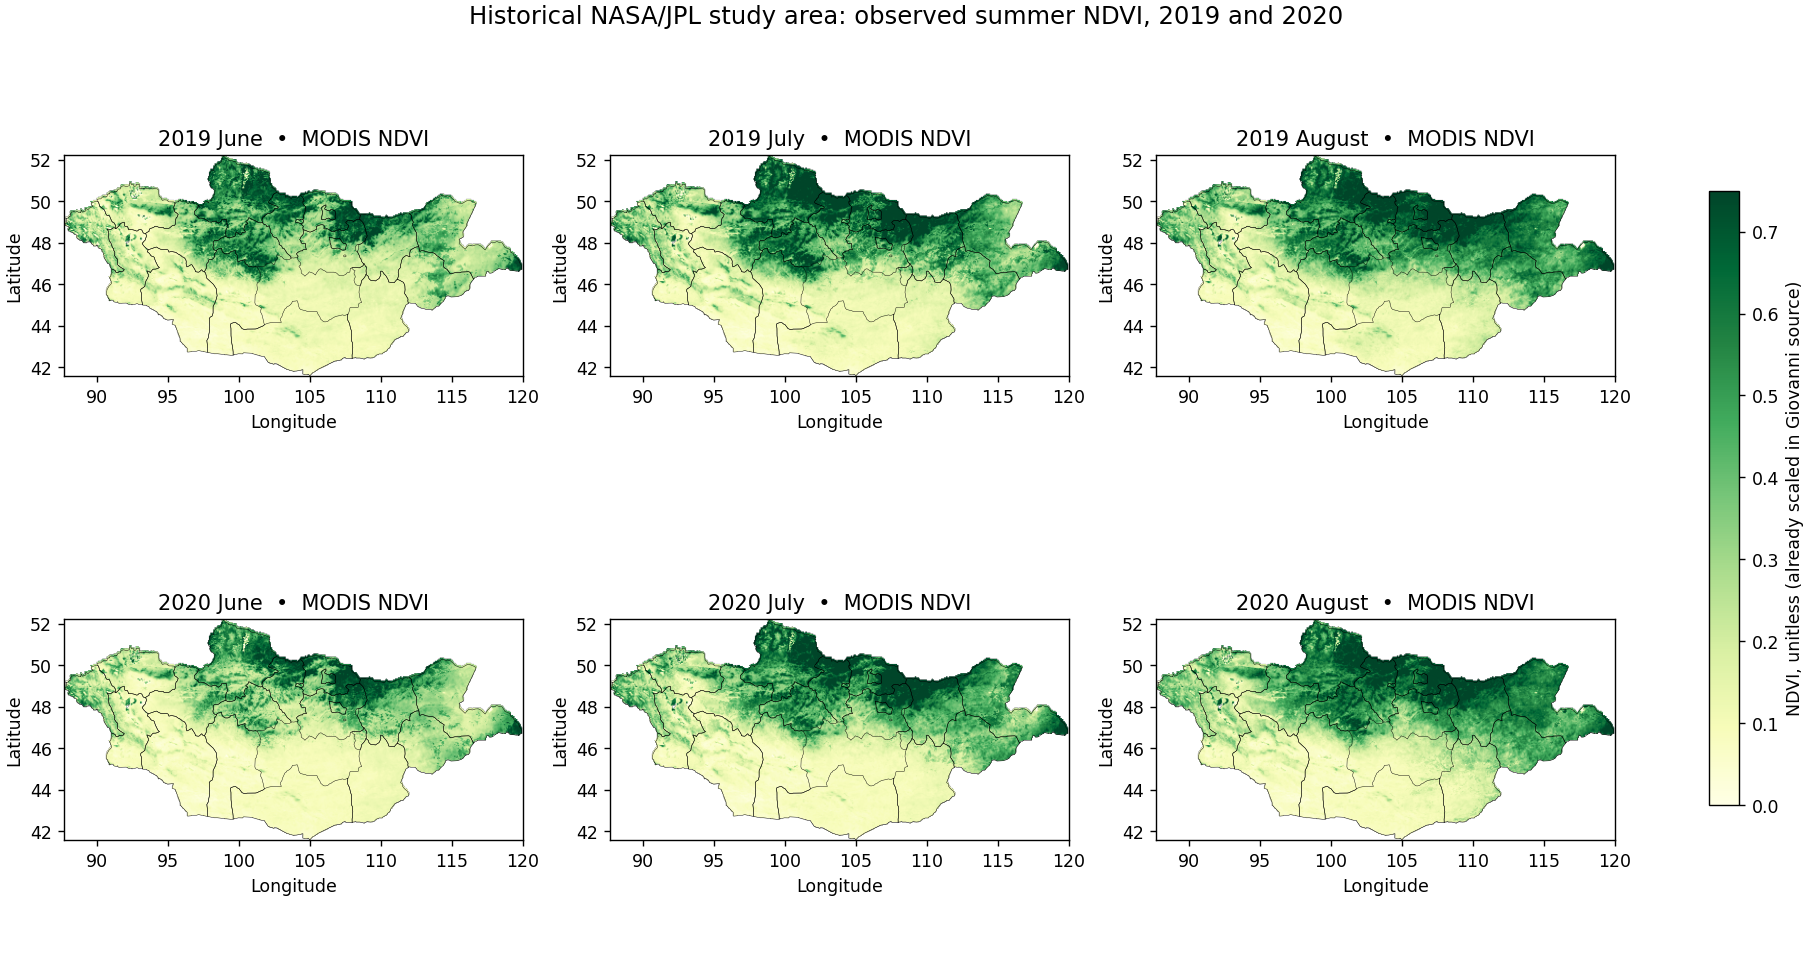

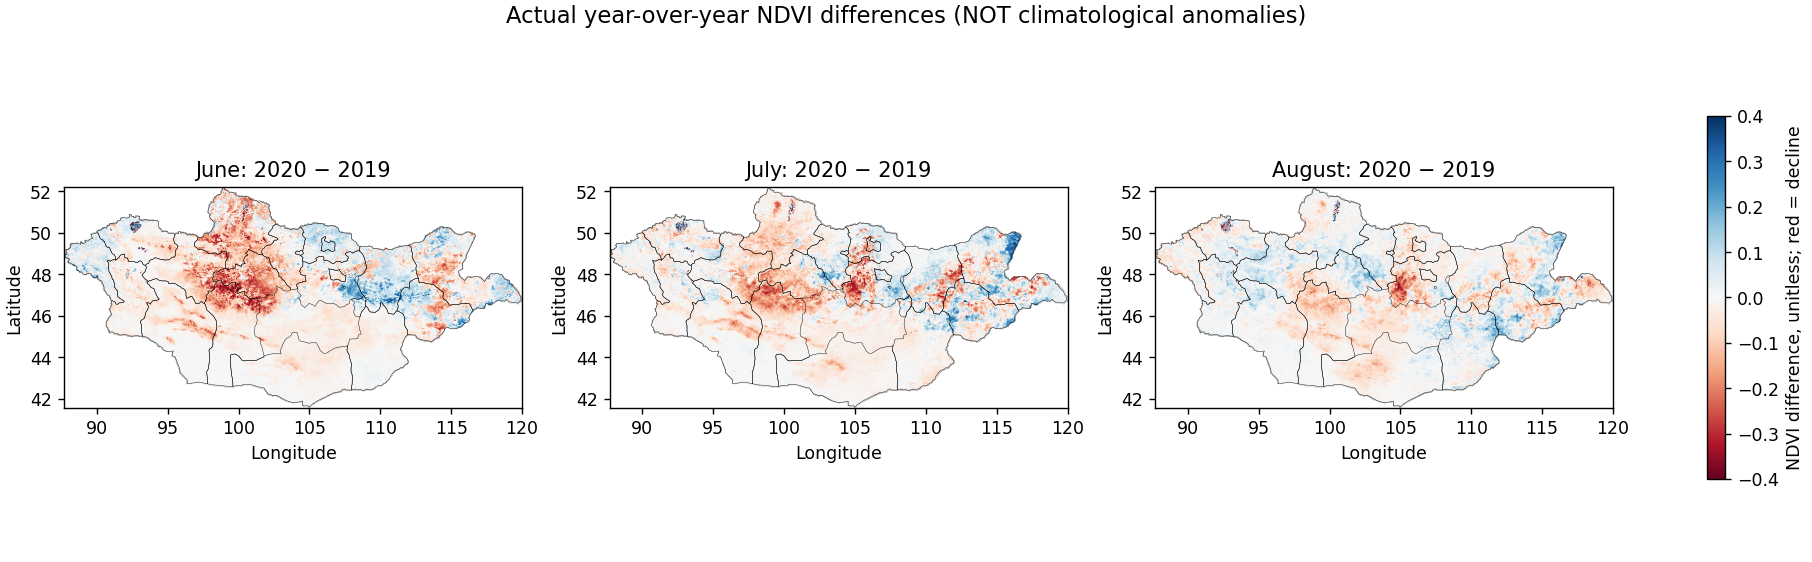

In [3]:
display(Image(filename=str(RESULTS/'01_ndvi_2019_2020_actual_observations.png'),width=1000))
display(Image(filename=str(RESULTS/'02_ndvi_year_over_year_difference.png'),width=1000))

## Exported machine-readable evidence
`results/ndvi_provincial_monthly_2019_2020.csv` and `results/ndvi_summer_comparison_by_province.csv` contain the calculations. Province polygons are repaired for original invalid topology before spatial masking.